<a href="https://colab.research.google.com/github/kikijamal/SemProject_MLEngine/blob/main/MobileNetV2_Final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. ## BUSINESS UNDERSTANDING

Small construction companies rent out construction equipment to prevent them from the long term financial capability. When the construction equipment is returned damage is often assessed through eyes which is unreliable and may not hold up


2.  ## DATA EXPLORATION
We explored different dataset but NEU (NORTHEASTERN UNIVERSITY) dataset stood out to us. This is because the data was well labelled, had many defect classes and there were enough images to train our model.

3. ## DATA PREPARATION ( CLEANING )
From the dataset, we got about 3600 entries , 1800 of which were images and 1800 xml notation. We found one duplicate image and deleted it.

In [ ]:
# Libraries  (numpy, pandas) plus plotting and image tools
import os
import zipfile
import hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

In [ ]:
# Connect Google Drive and unzip the NEU dataset (only the first time)
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = '/content/drive/MyDrive/SemProject/archive.zip'   # where the zip is stored
DATA_DIR = '/content/neu_dataset'                            # where we unzip it

if not os.path.exists(DATA_DIR):
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(DATA_DIR)
print('Dataset ready in', DATA_DIR)

Mounted at /content/drive
Dataset ready in /content/neu_dataset


In [ ]:
# List every file in the dataset folder and put it in a DataFrame
rows = []
for folder, _, files in os.walk(DATA_DIR):
    for name in files:
        rows.append({'path': os.path.join(folder, name), 'file_name': name})

df = pd.DataFrame(rows)
print(df.shape)      # (number of files, number of columns)
df.head(10)          # first 10 rows

(3600, 2)


,path,file_name
0,/content/neu_dataset/NEU-DET/train/annotations...,patches_113.xml
1,/content/neu_dataset/NEU-DET/train/annotations...,scratches_147.xml
2,/content/neu_dataset/NEU-DET/train/annotations...,pitted_surface_132.xml
3,/content/neu_dataset/NEU-DET/train/annotations...,scratches_83.xml
4,/content/neu_dataset/NEU-DET/train/annotations...,crazing_123.xml
5,/content/neu_dataset/NEU-DET/train/annotations...,crazing_140.xml
6,/content/neu_dataset/NEU-DET/train/annotations...,pitted_surface_45.xml
7,/content/neu_dataset/NEU-DET/train/annotations...,crazing_173.xml
8,/content/neu_dataset/NEU-DET/train/annotations...,crazing_219.xml
9,/content/neu_dataset/NEU-DET/train/annotations...,pitted_surface_25.xml


In [ ]:
# Work out the file type and the class (label) from the file name, e.g. crazing_1.jpg -> crazing
df['extension'] = df['file_name'].str.rsplit('.', n=1).str[-1].str.lower()
df['label'] = df['file_name'].str.rsplit('.', n=1).str[0].str.rsplit('_', n=1).str[0]

print(df['extension'].value_counts())   # which file types are in the folder
df.info()                                # columns, row count, data types

extension
xml    1800
jpg    1800
Name: count, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   path       3600 non-null   object
 1   file_name  3600 non-null   object
 2   extension  3600 non-null   object
 3   label      3600 non-null   object
dtypes: object(4)
memory usage: 112.6+ KB


In [ ]:
# A hash is a short code made from the file contents; identical files give identical codes
def file_hash(path):
    with open(path, 'rb') as f:
        return hashlib.md5(f.read()).hexdigest()

df['hash'] = df['path'].apply(file_hash)

print('Duplicate files:', df.duplicated(subset='hash').sum())

Duplicate files: 1


In [ ]:
# Show the duplicate file and the file it matches
dup_hash = df[df.duplicated(subset='hash')]['hash']
df[df['hash'].isin(dup_hash)][['file_name', 'extension', 'label', 'path']]

,file_name,extension,label,path
1747,patches_101.jpg,jpg,patches,/content/neu_dataset/NEU-DET/train/images/patc...
1914,patches_105.jpg,jpg,patches,/content/neu_dataset/NEU-DET/train/images/patc...


In [ ]:
# Keep the first copy of each file and drop the repeats
df = df.drop_duplicates(subset='hash')
print('Rows after removing duplicates:', df.shape[0])

Rows after removing duplicates: 3599


In [ ]:
image_types = ['jpg', 'jpeg', 'png', 'bmp']
print('Non-image files:', (~df['extension'].isin(image_types)).sum())

df = df[df['extension'].isin(image_types)]
print('Rows after keeping images only:', df.shape[0])

Non-image files: 1800
Rows after keeping images only: 1799


In [ ]:
widths, heights, modes, readable = [], [], [], []

for path in df['path']:
    try:
        img = Image.open(path)
        img.load()                       # forces the file to be fully read
        widths.append(img.size[0])
        heights.append(img.size[1])
        modes.append(img.mode)           # 'L' = grayscale, 'RGB' = colour
        readable.append(True)
    except Exception:
        widths.append(None); heights.append(None); modes.append(None)
        readable.append(False)

df['width'] = widths
df['height'] = heights
df['mode'] = modes
df['readable'] = readable

print('Unreadable images:', (~df['readable']).sum())

Unreadable images: 0


In [ ]:
expected = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']

print('Labels found:', sorted(df['label'].unique()))

# Rows whose label is not one of the six expected classes
wrong = df[~df['label'].isin(expected)]
print('Rows with an unexpected label:', wrong.shape[0])

Labels found: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
Rows with an unexpected label: 0


In [ ]:
print(df.isnull().sum())     # number of missing values in each column

path         0
file_name    0
extension    0
label        0
hash         0
width        0
height       0
mode         0
readable     0
dtype: int64


        width  height
count  1799.0  1799.0
mean    200.0   200.0
std       0.0     0.0
min     200.0   200.0
25%     200.0   200.0
50%     200.0   200.0
75%     200.0   200.0
max     200.0   200.0


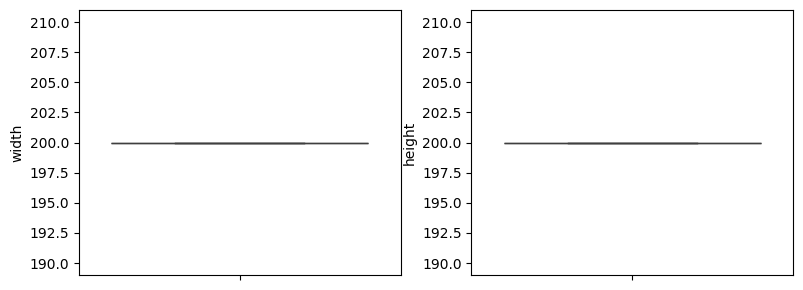

In [ ]:
print(df[['width', 'height']].describe())   # summary statistics

plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1)
sns.boxplot(y='width', data=df)      # boxplot method from class
plt.subplot(1, 2, 2)
sns.boxplot(y='height', data=df)
plt.tight_layout()
plt.show()

In [ ]:
# How many images there are of each size and colour mode
print(df.groupby(['width', 'height', 'mode']).size())

width  height  mode
200    200     RGB     1799
dtype: int64


In [ ]:
df = df.reset_index(drop=True)

CLEAN_CSV = '/content/drive/MyDrive/SemProject/clean_data.csv'
df.to_csv(CLEAN_CSV, index=False)      # export, as shown in class

print('Clean images:', df.shape[0])
print(df['label'].value_counts())      # images per class after cleaning

Clean images: 1799
label
rolled-in_scale    300
inclusion          300
pitted_surface     300
crazing            300
scratches          300
patches            299
Name: count, dtype: int64


 4. ##EXPLORATORY DATA ANALYSIS (EDA)

 The chart shows all six classes have about 300 images meaning each class is balanced. The sample images show what each defect look like.


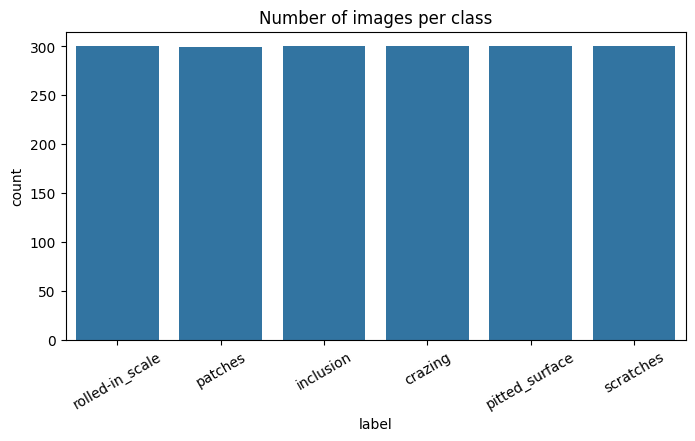

In [ ]:
# Bar chart of how many images each class has
plt.figure(figsize=(8, 4))
sns.countplot(x='label', data=df)
plt.title('Number of images per class')
plt.xticks(rotation=30)
plt.show()

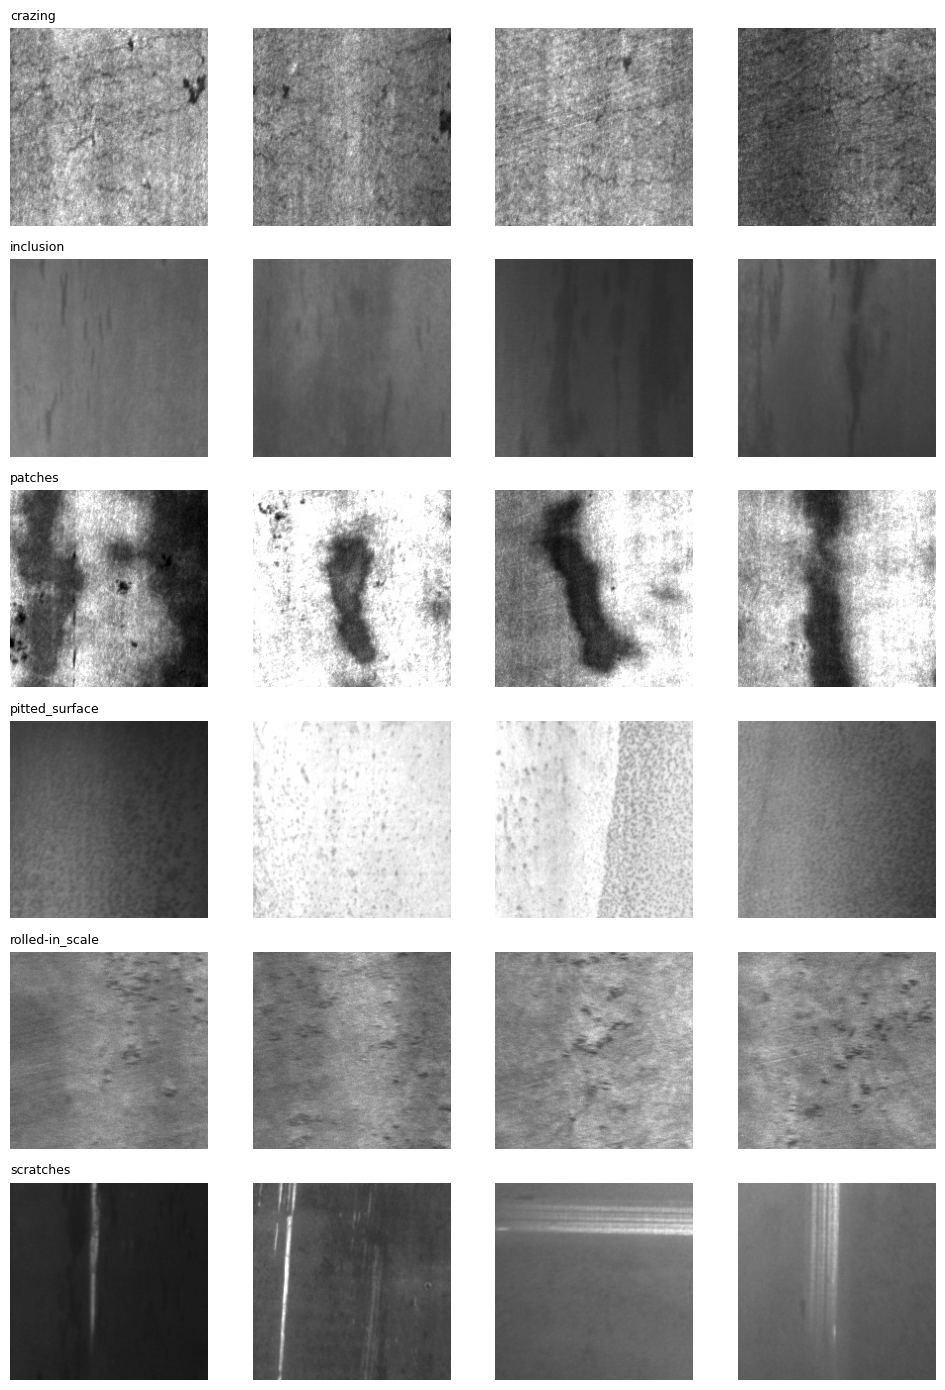

In [ ]:
# Show 4 random images from each class (rows = classes)
classes = sorted(df['label'].unique())

plt.figure(figsize=(10, 14))
n = 1
for c in classes:
    samples = df[df['label'] == c].sample(4, random_state=1)
    for path in samples['path']:
        plt.subplot(6, 4, n)
        plt.imshow(Image.open(path))
        plt.axis('off')
        if n % 4 == 1:
            plt.title(c, loc='left', fontsize=9)   # class name above the first image of each row
        n += 1
plt.tight_layout()
plt.show()

Images where R = G = B: 1799 of 1799
                 count        mean        std        min         25%  \
label                                                                  
crazing          300.0  141.107116  28.668897  60.224950  119.115013   
inclusion        300.0  106.366375  33.873650  49.893825   84.896556   
patches          299.0  132.564614  43.126494  35.567475  105.961737   
pitted_surface   300.0  176.665727  49.347109  44.465675  148.076819   
rolled-in_scale  300.0  117.912608  24.624031  68.810200   93.289062   
scratches        300.0   95.145790  29.087728  34.336950   73.343131   

                        50%         75%         max  
label                                                
crazing          149.028363  164.862088  183.593225  
inclusion         99.399000  116.360838  233.433925  
patches          139.601200  162.533062  223.669750  
pitted_surface   186.357200  217.778894  246.112525  
rolled-in_scale  125.867463  136.659937  160.962750  
scratche

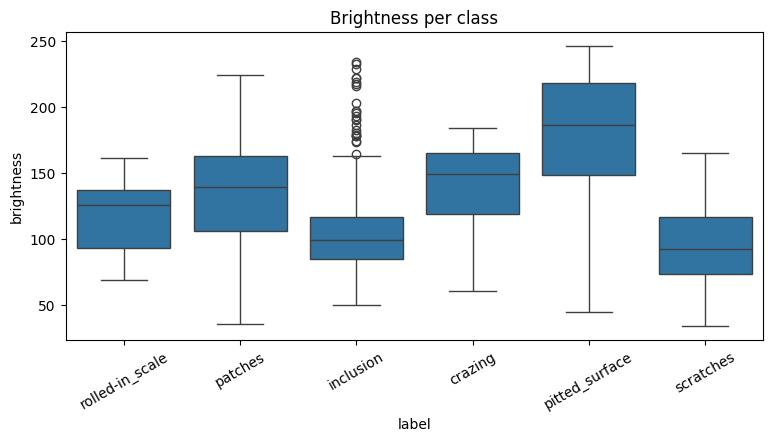

In [ ]:
# Average brightness of each image (0 = black, 255 = white)
# and a check on whether the 3 colour channels (R, G, B) are identical
brightness = []
same_channels = []

for path in df['path']:
    img = np.array(Image.open(path))          # image as numbers, shape (200, 200, 3)
    brightness.append(img.mean())
    same_channels.append(bool((img[:, :, 0] == img[:, :, 1]).all() and (img[:, :, 1] == img[:, :, 2]).all()))

df['brightness'] = brightness
df['same_channels'] = same_channels

print('Images where R = G = B:', df['same_channels'].sum(), 'of', df.shape[0])
print(df.groupby('label')['brightness'].describe())   # brightness summary per class

plt.figure(figsize=(9, 4))
sns.boxplot(x='label', y='brightness', data=df)     # boxplot method from class
plt.xticks(rotation=30)
plt.title('Brightness per class')
plt.show()

4.## DATA PREPARATION : TRAINING, VALIDATION AND TEST SPLIT

We split the data (1800) into training 1400 validation 200 and testing 200 sets. Each set has about the same number of defect images across the three sets.

In [ ]:
import os, zipfile, numpy as np, pandas as pd
from PIL import Image

BASE_DIR = '/content/drive/MyDrive/SemProject'
if not os.path.exists('/content/neu_dataset'):
    with zipfile.ZipFile(f'{BASE_DIR}/archive.zip') as z:
        z.extractall('/content/neu_dataset')

df = pd.read_csv(f'{BASE_DIR}/split_data.csv')

class_names = sorted(df['label'].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}
print(class_to_idx)

# find every original image by file name
local = {}
for root, _, files in os.walk('/content/neu_dataset'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            local[f] = os.path.join(root, f)
print('original images found:', len(local))

def load(split):
    sub = df[(df['split'] == split) & (df['file_name'].isin(local))]
    X = np.array([np.array(Image.open(local[f]).convert('RGB').resize((224, 224)))
                  for f in sub['file_name']], dtype='float32')
    y = sub['label'].map(class_to_idx).values
    return X, y

X_train, y_train = load('train')
X_val,   y_val   = load('validation')
X_test,  y_test  = load('test')
print(X_train.shape, X_val.shape, X_test.shape)
print(np.bincount(y_train), np.bincount(y_val), np.bincount(y_test))

{'crazing': 0, 'inclusion': 1, 'patches': 2, 'pitted_surface': 3, 'rolled-in_scale': 4, 'scratches': 5}
original images found: 1800
(1399, 224, 224, 3) (200, 224, 224, 3) (200, 224, 224, 3)
[233 233 233 234 233 233] [33 34 33 33 33 34] [34 33 33 33 34 33]


In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks

tf.keras.utils.set_random_seed(42)

# augmentation: applied during training only (Keras switches it off for validation/test)
augment = models.Sequential([
    layers.RandomRotation(15/360),
    layers.RandomTranslation(0.1, 0.1, fill_mode='reflect'),
    layers.RandomZoom(0.1, fill_mode='reflect'),
    layers.RandomFlip('horizontal_and_vertical'),
])

base_model = tf.keras.applications.MobileNetV2(input_shape=(224, 224, 3),
                                         include_top=False, weights='imagenet')
base_model.trainable = False

inputs = layers.Input(shape=(224, 224, 3))
x = augment(inputs)
x = layers.Rescaling(1/127.5, offset=-1)(x)   # MobileNetV2's expected input range
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation='relu')(x)
outputs = layers.Dense(6, activation='softmax')(x)    # 6 defect types
model = models.Model(inputs, outputs)

model.compile(optimizer=tf.keras.optimizers.Adam(0.001),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])

ckpt = '/content/drive/MyDrive/SemProject/model_six_class.keras'
cbs = [callbacks.EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True),
       callbacks.ModelCheckpoint(ckpt, monitor='val_loss', save_best_only=True)]

history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=15, batch_size=32, callbacks=cbs, verbose=2)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
44/44 - 20s - 466ms/step - accuracy: 0.8735 - loss: 0.3927 - val_accuracy: 0.9800 - val_loss: 0.0867
Epoch 2/15
44/44 - 4s - 87ms/step - accuracy: 0.9828 - loss: 0.0521 - val_accuracy: 0.9850 - val_loss: 0.0399
Epoch 3/15
44/44 - 3s - 79ms/step - accuracy: 0.9893 - loss: 0.0356 - val_accuracy: 0.9950 - val_loss: 0.0236
Epoch 4/15
44/44 - 3s - 65ms/step - accuracy: 0.9943 - loss: 0.0217 - val_accuracy: 0.9900 - val_loss: 0.0494
Epoch 5/15
44/44 - 6s - 129ms/step - accuracy: 0.9950 - loss: 0.0167 - val_accuracy: 0.9850 - val_loss: 0.0415
Epoch 6/15
44/44 - 5s - 106ms/step - accuracy: 0.9950 - loss: 0.0188 - val_accuracy: 0.9900 - val_loss: 0.0295
Epoch 7/15
44/44 - 3s - 66ms/step - accuracy: 0.9950 - loss: 0.0164 - val_accuracy: 0.9850 - val_loss: 0.0326


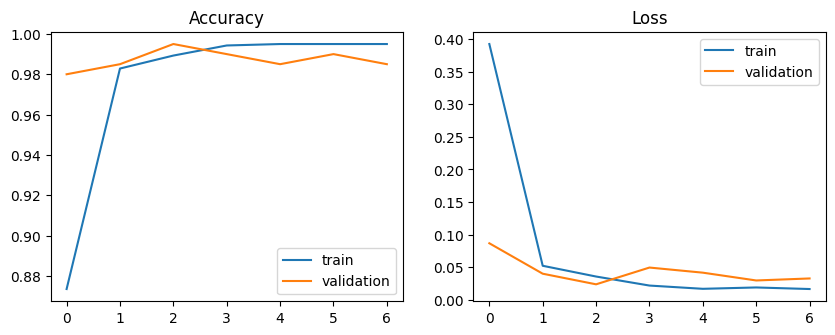

In [ ]:
plt.figure(figsize=(10, 3.5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='validation')
plt.title('Accuracy'); plt.legend()
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='train')
plt.plot(history.history['val_loss'], label='validation')
plt.title('Loss'); plt.legend()
plt.show()

Test accuracy: 1.0
Correct: 200 of 200

                 precision    recall  f1-score   support

        crazing       1.00      1.00      1.00        34
      inclusion       1.00      1.00      1.00        33
        patches       1.00      1.00      1.00        33
 pitted_surface       1.00      1.00      1.00        33
rolled-in_scale       1.00      1.00      1.00        34
      scratches       1.00      1.00      1.00        33

       accuracy                           1.00       200
      macro avg       1.00      1.00      1.00       200
   weighted avg       1.00      1.00      1.00       200

Cohen kappa: 1.0


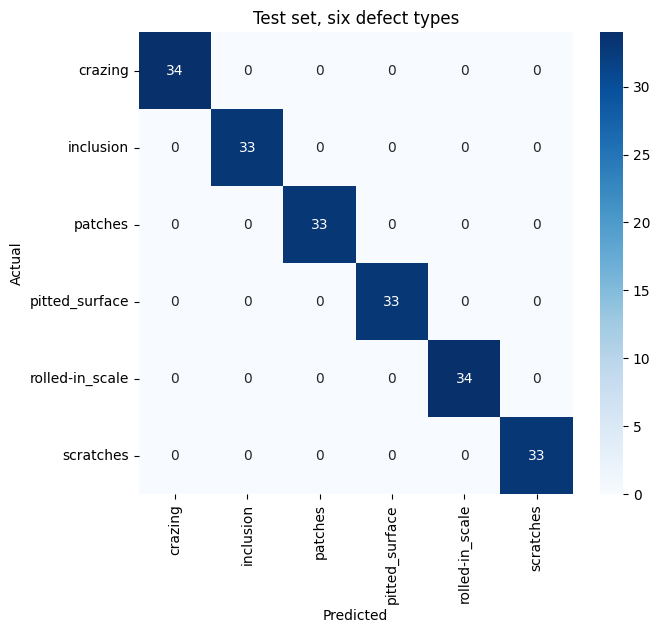

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, cohen_kappa_score
import seaborn as sns, matplotlib.pyplot as plt

probs = model.predict(X_test, verbose=0)
pred = probs.argmax(axis=1)

print('Test accuracy:', (pred == y_test).mean())
print('Correct:', (pred == y_test).sum(), 'of', len(y_test))
print()
print(classification_report(y_test, pred, target_names=class_names, digits=2))
print('Cohen kappa:', round(cohen_kappa_score(y_test, pred), 3))

cm = confusion_matrix(y_test, pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Test set, six defect types')
plt.show()

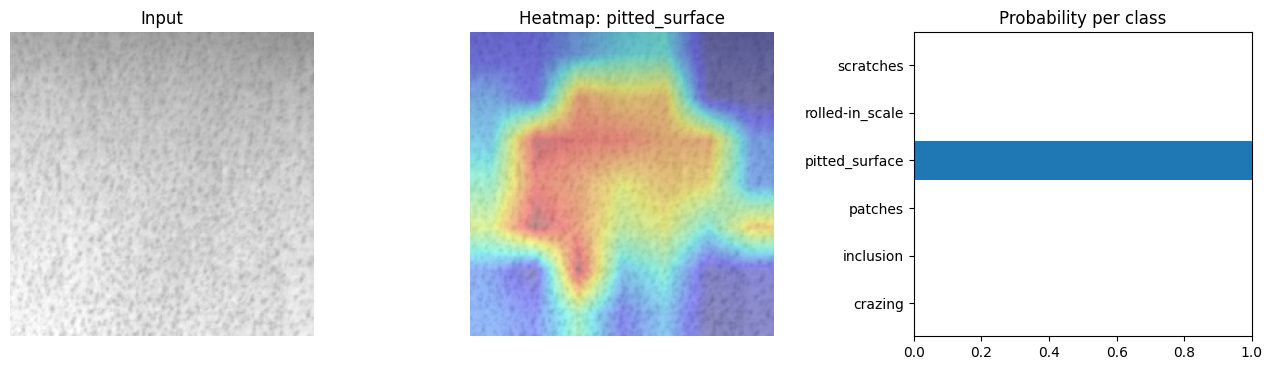

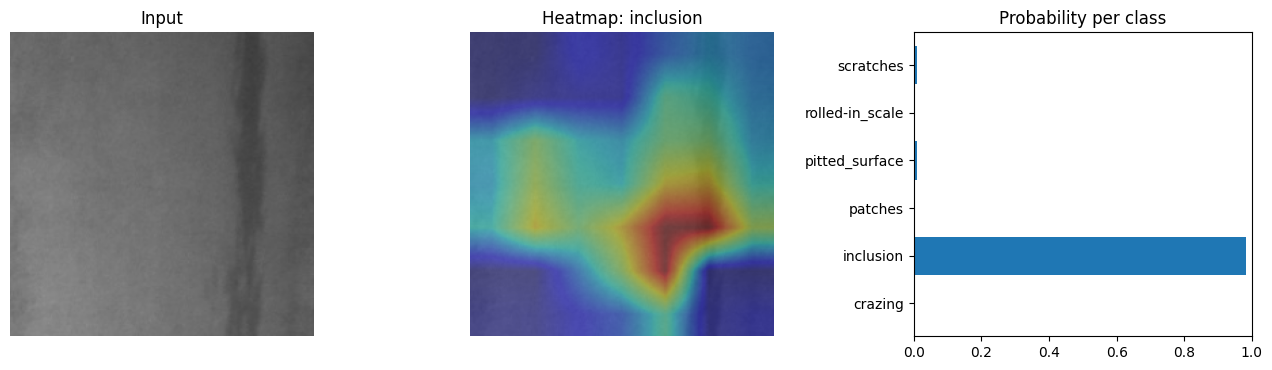

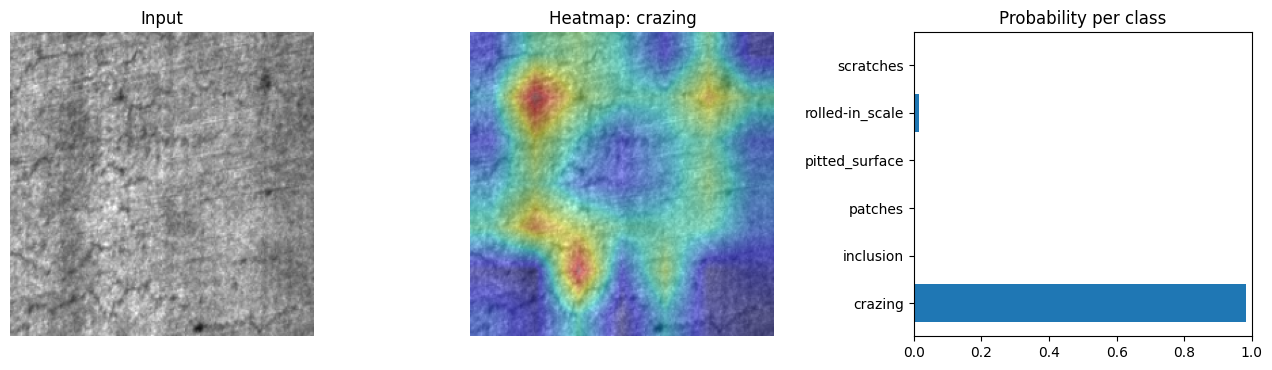

In [ ]:
inner = next(l for l in model.layers if 'mobilenet' in l.name.lower())   # the MobileNetV2 base
i = model.layers.index(inner)
pre  = [l for l in model.layers[:i] if not isinstance(l, tf.keras.layers.InputLayer)]
head = model.layers[i+1:]

def gradcam(img):
    x = tf.convert_to_tensor(img[None], dtype=tf.float32)
    for l in pre: x = l(x, training=False)
    with tf.GradientTape() as tape:
        fmap = inner(x, training=False)
        tape.watch(fmap)
        out = fmap
        for l in head: out = l(out, training=False)
        c = int(tf.argmax(out[0]))
        score = out[:, c]
    grads = tape.gradient(score, fmap)
    w = tf.reduce_mean(grads, axis=(0, 1, 2))
    cam = tf.nn.relu(tf.reduce_sum(fmap[0] * w, axis=-1)).numpy()
    return cam / (cam.max() + 1e-8), c, out[0].numpy()

def explain(img):                      # img: 224x224x3, pixel values 0-255
    cam, c, p = gradcam(img)
    cam = tf.image.resize(cam[..., None], (224, 224)).numpy()[..., 0]
    fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))
    ax[0].imshow(img.astype('uint8')); ax[0].set_title('Input'); ax[0].axis('off')
    ax[1].imshow(img.astype('uint8')); ax[1].imshow(cam, cmap='jet', alpha=0.4)
    ax[1].set_title(f'Heatmap: {class_names[c]}'); ax[1].axis('off')
    ax[2].barh(class_names, p); ax[2].set_xlim(0, 1); ax[2].set_title('Probability per class')
    plt.tight_layout(); plt.show()

for k in [0, 60, 120]:
    explain(X_test[k])

Result: pitted_surface | confidence: 1.0


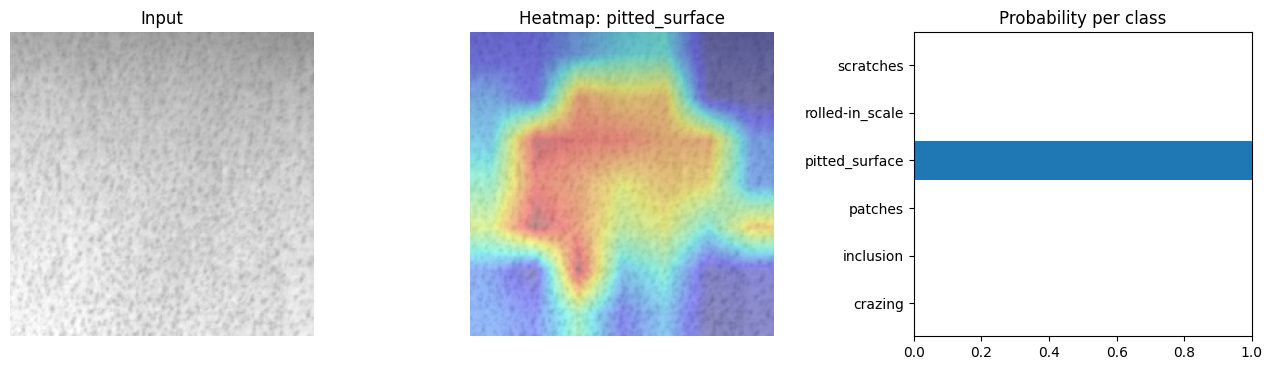

In [ ]:
def predict_image(path, thr=0.98):
    img = np.array(Image.open(path).convert('RGB').resize((224, 224))).astype('float32')
    p = model.predict(img[None], verbose=0)[0]
    label = class_names[int(p.argmax())] if p.max() >= thr else 'NOT CLASSIFIABLE'
    print('Result:', label, '| confidence:', round(float(p.max()), 3))
    explain(img)

# Try it on one NEU image and one equipment photo
neu_path = local[df[df['split'] == 'test']['file_name'].iloc[0]]
predict_image(neu_path)

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os, zipfile, numpy as np, pandas as pd
from PIL import Image

BASE_DIR = '/content/drive/MyDrive/SemProject'
if not os.path.exists('/content/neu_dataset'):
    with zipfile.ZipFile(f'{BASE_DIR}/archive.zip') as z:
        z.extractall('/content/neu_dataset')

df = pd.read_csv(f'{BASE_DIR}/split_data.csv')
class_names = sorted(df['label'].unique())
class_to_idx = {c: i for i, c in enumerate(class_names)}

local = {}
for root, _, files in os.walk('/content/neu_dataset'):
    for f in files:
        if f.lower().endswith(('.jpg', '.jpeg', '.png', '.bmp')):
            local[f] = os.path.join(root, f)

def load(split):
    sub = df[(df['split'] == split) & (df['file_name'].isin(local))]
    X = np.array([np.array(Image.open(local[f]).convert('RGB').resize((224, 224)))
                  for f in sub['file_name']], dtype='float32')
    y = sub['label'].map(class_to_idx).values
    return X, y

X_train, y_train = load('train')
X_val,   y_val   = load('validation')
X_test,  y_test  = load('test')
print(X_train.shape, X_val.shape, X_test.shape)

import tensorflow as tf
print('GPU:', tf.config.list_physical_devices('GPU'))

Mounted at /content/drive
(1399, 224, 224, 3) (200, 224, 224, 3) (200, 224, 224, 3)
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import time, numpy as np, pandas as pd, tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import (MobileNetV2, ResNet50, VGG16,
                                           DenseNet121, EfficientNetB0)
from tensorflow.keras.applications import (mobilenet_v2, resnet50, vgg16,
                                           densenet, efficientnet)
from sklearn.metrics import cohen_kappa_score

candidates = {
    'MobileNetV2':    (MobileNetV2,    mobilenet_v2.preprocess_input),
    'ResNet50':       (ResNet50,       resnet50.preprocess_input),
    'VGG16':          (VGG16,          vgg16.preprocess_input),
    'DenseNet121':    (DenseNet121,    densenet.preprocess_input),
    'EfficientNetB0': (EfficientNetB0, efficientnet.preprocess_input),
}

results = []
for name, (builder, prep) in candidates.items():
    t0 = time.time()
    tf.keras.utils.set_random_seed(42)
    base = builder(include_top=False, weights='imagenet',
                   input_shape=(224, 224, 3), pooling='avg')
    # frozen base: extract features once from each image set
    Ftr = base.predict(prep(X_train.copy()), batch_size=32, verbose=0)
    Fva = base.predict(prep(X_val.copy()),   batch_size=32, verbose=0)
    Fte = base.predict(prep(X_test.copy()),  batch_size=32, verbose=0)

    # the same small classifier head for every network
    head = models.Sequential([
        layers.Input(shape=(Ftr.shape[1],)),
        layers.Dropout(0.3),
        layers.Dense(128, activation='relu'),
        layers.Dense(6, activation='softmax')])
    head.compile(optimizer=tf.keras.optimizers.Adam(0.001),
                 loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    head.fit(Ftr, y_train, validation_data=(Fva, y_val), epochs=30, batch_size=32,
             verbose=0,
             callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=4,
                                                restore_best_weights=True)])
    pred = head.predict(Fte, verbose=0).argmax(axis=1)
    results.append({'Model': name,
                    'Base parameters (millions)': round(base.count_params() / 1e6, 1),
                    'Test accuracy': round(float((pred == y_test).mean()), 3),
                    'Correct of 200': int((pred == y_test).sum()),
                    'Kappa': round(float(cohen_kappa_score(y_test, pred)), 3),
                    'Minutes': round((time.time() - t0) / 60, 1)})
    print(results[-1])

print()
print(pd.DataFrame(results).to_string(index=False))

{'Model': 'MobileNetV2', 'Base parameters (millions)': 2.3, 'Test accuracy': 1.0, 'Correct of 200': 200, 'Kappa': 1.0, 'Minutes': 1.2}
94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
{'Model': 'ResNet50', 'Base parameters (millions)': 23.6, 'Test accuracy': 1.0, 'Correct of 200': 200, 'Kappa': 1.0, 'Minutes': 1.0}
58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
{'Model': 'VGG16', 'Base parameters (millions)': 14.7, 'Test accuracy': 1.0, 'Correct of 200': 200, 'Kappa': 1.0, 'Minutes': 1.0}
29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
{'Model': 'DenseNet121', 'Base parameters (millions)': 7.0, 'Test accuracy': 1.0, 'Correct of 200': 200, 'Kappa': 1.0, 'Minutes': 2.8}
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
{'Model': 'EfficientNetB0', 'Base parameters (millions)': 4.0, 'Test accuracy': 1.0, 'Correct of 200': 200, 'Kappa': 1.0, 'Minutes': 1.4}

         Model  Base parameters (millions)  Test accuracy  Correct of 200  Kappa  Minutes
   MobileNetV2                    

In [ ]:
import time, numpy as np, pandas as pd, tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from tensorflow.keras.applications import (MobileNetV2, ResNet50, VGG16,
                                           DenseNet121, EfficientNetB0)
from tensorflow.keras.applications import (mobilenet_v2, resnet50, vgg16,
                                           densenet, efficientnet)
from sklearn.model_selection import StratifiedKFold, train_test_split

X_all = np.concatenate([X_train, X_val, X_test])
y_all = np.concatenate([y_train, y_val, y_test])
print('all images:', X_all.shape, np.bincount(y_all))

candidates = {
    'MobileNetV2':    (MobileNetV2,    mobilenet_v2.preprocess_input),
    'ResNet50':       (ResNet50,       resnet50.preprocess_input),
    'VGG16':          (VGG16,          vgg16.preprocess_input),
    'DenseNet121':    (DenseNet121,    densenet.preprocess_input),
    'EfficientNetB0': (EfficientNetB0, efficientnet.preprocess_input),
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
summary = []

for name, (builder, prep) in candidates.items():
    t0 = time.time()
    base = builder(include_top=False, weights='imagenet',
                   input_shape=(224, 224, 3), pooling='avg')
    F = base.predict(prep(X_all.copy()), batch_size=32, verbose=0)  # frozen features, once

    fold_acc = []
    for k, (tr, te) in enumerate(skf.split(F, y_all), start=1):
        # keep 10% of the training part aside only to decide when to stop
        tr_fit, tr_stop = train_test_split(tr, test_size=0.1,
                                           stratify=y_all[tr], random_state=42)
        tf.keras.utils.set_random_seed(42)
        head = models.Sequential([
            layers.Input(shape=(F.shape[1],)),
            layers.Dropout(0.3),
            layers.Dense(128, activation='relu'),
            layers.Dense(6, activation='softmax')])
        head.compile(optimizer=tf.keras.optimizers.Adam(0.001),
                     loss='sparse_categorical_crossentropy', metrics=['accuracy'])
        head.fit(F[tr_fit], y_all[tr_fit],
                 validation_data=(F[tr_stop], y_all[tr_stop]),
                 epochs=30, batch_size=32, verbose=0,
                 callbacks=[callbacks.EarlyStopping(monitor='val_loss', patience=4,
                                                    restore_best_weights=True)])
        pred = head.predict(F[te], verbose=0).argmax(axis=1)
        fold_acc.append(float((pred == y_all[te]).mean()))

    summary.append({'Model': name,
                    'Fold accuracies (%)': ', '.join(f'{a*100:.1f}' for a in fold_acc),
                    'Mean (%)': round(np.mean(fold_acc) * 100, 2),
                    'SD (pp)': round(np.std(fold_acc, ddof=1) * 100, 2),
                    'Minutes': round((time.time() - t0) / 60, 1)})
    print(summary[-1])

print()
print(pd.DataFrame(summary).to_string(index=False))

all images: (1799, 224, 224, 3) [300 300 299 300 300 300]
{'Model': 'MobileNetV2', 'Fold accuracies (%)': '99.4, 99.4, 100.0, 100.0, 100.0', 'Mean (%)': np.float64(99.78), 'SD (pp)': np.float64(0.3), 'Minutes': 1.2}
{'Model': 'ResNet50', 'Fold accuracies (%)': '100.0, 100.0, 99.4, 100.0, 99.7', 'Mean (%)': np.float64(99.83), 'SD (pp)': np.float64(0.25), 'Minutes': 1.0}
{'Model': 'VGG16', 'Fold accuracies (%)': '100.0, 100.0, 100.0, 100.0, 99.4', 'Mean (%)': np.float64(99.89), 'SD (pp)': np.float64(0.25), 'Minutes': 1.0}
{'Model': 'DenseNet121', 'Fold accuracies (%)': '99.4, 99.4, 100.0, 99.7, 100.0', 'Mean (%)': np.float64(99.72), 'SD (pp)': np.float64(0.28), 'Minutes': 2.0}
{'Model': 'EfficientNetB0', 'Fold accuracies (%)': '98.9, 99.4, 100.0, 100.0, 100.0', 'Mean (%)': np.float64(99.67), 'SD (pp)': np.float64(0.5), 'Minutes': 1.3}

         Model              Fold accuracies (%)  Mean (%)  SD (pp)  Minutes
   MobileNetV2  99.4, 99.4, 100.0, 100.0, 100.0     99.78     0.30      1.2
  

6.## MODELLING
 Our main aim was to transfer the concept of laboratory controlled images to real world life scenario where images taken by ordinary contractors would applu


7.## EVALUATION
The test result emerged 1.0 from cohen's kappa testing which removes all aspect of guessing.

In [ ]:
import os, numpy as np, tensorflow as tf
from PIL import Image
from google.colab import drive
drive.mount('/content/drive')

base = '/content/drive/MyDrive/SemProject'
model = tf.keras.models.load_model(f'{base}/model_six_class.keras')
classes = ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']
THRESHOLD = 0.98
exts = ('.jpg', '.jpeg', '.png')

# ---- The cut-off, ready to reuse ----
def classify(path, thr=THRESHOLD):
    img = np.array(Image.open(path).convert('RGB').resize((224, 224))).astype('float32')
    probs = model.predict(img[None], verbose=0)[0]
    conf = float(probs.max())
    if conf < thr:
        return 'NOT CLASSIFIABLE', conf
    return classes[int(probs.argmax())], conf

# ---- Real equipment photos only (steel-named files removed) ----
pilot = [os.path.join(r, f) for r, d, fs in os.walk(f'{base}/field_pilot') for f in fs if f.lower().endswith(exts)]
others = [os.path.join(r, f) for r, d, fs in os.walk(f'{base}/split_images') for f in fs
          if f.lower().endswith(exts) and not f.startswith('frame')]
paths = sorted(p for p in set(pilot + others) if not os.path.basename(p).startswith(tuple(classes)))

X = np.array([np.array(Image.open(p).convert('RGB').resize((224, 224))).astype('float32') for p in paths])
probs = model.predict(X, batch_size=32, verbose=0)
conf = probs.max(axis=1)
accepted = conf >= THRESHOLD

print('real equipment photos:', len(paths))
print('NOT CLASSIFIABLE:', (~accepted).sum(), f'({(~accepted).mean()*100:.1f}%)')
print('classified:', accepted.sum())
print('median confidence:', np.median(conf).round(3))

# Example of using it on one photo:
print(classify(paths[0]))

Mounted at /content/drive
real equipment photos: 175
NOT CLASSIFIABLE: 153 (87.4%)
classified: 22
median confidence: 0.808
('NOT CLASSIFIABLE', 0.8515287637710571)


8.## GRAD CAM EXPLAINABILITY.
a heatmap of the parts of the image that pushed the model towards its answer. Red areas mattered most. Therefore, you can see whether the model looked at the defect or at something irrelevant.

9.## DEPLOYMENT
TFLITE is a a small version of the model that runs on a phone (2.7 MB). The app has to send a 224×224 colour image with pixel values 0–255, and no division by 255. Probabilities come back six probabilities, in the order of labels.txt

10.## LIMITATIONS AND CONCLUSIONS
The model was trained on clean NEU steel images meaning it was very easy to train it and test it. We needed another harder dataset to test it. We managed to achieved a a working, explainable, phone-ready steel-defect classifier and a tested method.